In [2]:
class MLP:
    def __init__(self, layer_sizes, activation="tanh"):
        self.layer_sizes = layer_sizes
        self.activation = activation
        self.W, self.b = [], []
        self.Z_list, self.A_list = [], []
        self.dW_list, self.db_list = [], []
        for i in range(len(layer_sizes) - 1):
            in_dim, out_dim = layer_sizes[i], layer_sizes[i + 1]
            self.W.append(np.random.randn(in_dim, out_dim) * 0.1)
            self.b.append(np.zeros((1, out_dim)))

    def _activate(self, Z):
        if self.activation == "sigmoid":
            return 1 / (1 + np.exp(-Z))
        elif self.activation == "relu":
            return np.maximum(0, Z)
        elif self.activation == "tanh":
            return np.tanh(Z)
        else:
            raise ValueError(self.activation)

    def _dactivate(self, Z):
        if self.activation == "sigmoid":
            s = 1 / (1 + np.exp(-Z))
            return s * (1 - s)
        elif self.activation == "relu":
            return (Z > 0).astype(float)
        elif self.activation == "tanh":
            return 1 - np.tanh(Z) ** 2

    def forward(self, X):
        self.Z_list, self.A_list = [], []
        A = X
        self.A_list.append(A)
        for i in range(len(self.W)):
            Z = A.dot(self.W[i]) + self.b[i]
            self.Z_list.append(Z)
            A = self._activate(Z) if i < len(self.W) - 1 else Z
            self.A_list.append(A)
        return A

    def mse(self, y_pred, y_true):
        return np.mean((y_pred - y_true) ** 2)

    def backward(self, y_true):
        m = y_true.shape[0]
        # выходной слой
        aL, zL = self.A_list[-1], self.Z_list[-1]
        delta = 2 * (aL - y_true) / m
        # градиенты выхода
        a_prev = self.A_list[-2]
        dW = a_prev.T.dot(delta)
        db = np.sum(delta, axis=0, keepdims=True)
        self.dW_list, self.db_list = [dW], [db]
        # скрытые
        for l in range(len(self.layer_sizes) - 2, 0, -1):
            z = self.Z_list[l - 1]
            a_prev = self.A_list[l - 1]
            W_next = self.W[l]
            delta = delta.dot(W_next.T) * self._dactivate(z)
            dW = a_prev.T.dot(delta)
            db = np.sum(delta, axis=0, keepdims=True)
            self.dW_list.insert(0, dW)
            self.db_list.insert(0, db)

    def update_params(self, lr):
        # Обновляем веса и смещения
        for i in range(len(self.W)):
            # Обновляем веса W и смещения b.
            #  W[i] -= lr * dW_list[i]
            self.W[i] -= lr * self.dW_list[i]
            #  b[i] -= lr * db_list[i]
            self.b[i] -= lr * self.db_list[i]

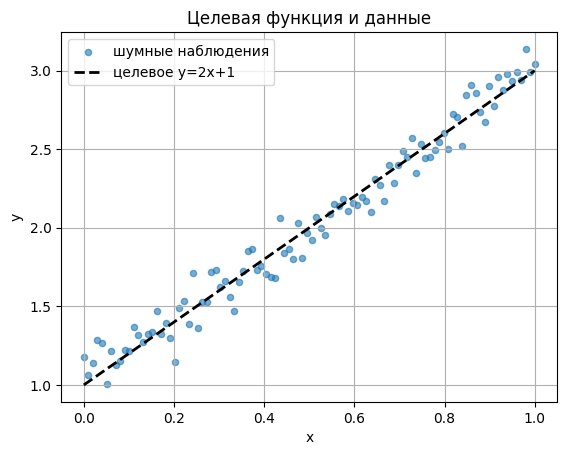

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# Данные
np.random.seed(0)
X = np.linspace(0, 1, 100)[:, None]  # (100,1)
Y = 2 * X + 1 + np.random.randn(100, 1) * 0.1  # шумные точки

# Визуализация
plt.scatter(X, Y, s=20, alpha=0.6, label="шумные наблюдения")
# Чистая прямая y=2x+1
x_line = np.linspace(0, 1, 100)
plt.plot(x_line, 2 * x_line + 1, "k--", linewidth=2, label="целевое y=2x+1")
plt.title("Целевая функция и данные")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

Epoch  2: loss=2.2299, ||grad||=3.2996
Epoch  4: loss=0.7483, ||grad||=1.8418
Epoch  6: loss=0.2859, ||grad||=1.0322
Epoch  8: loss=0.1399, ||grad||=0.5853
Epoch 10: loss=0.0923, ||grad||=0.3429


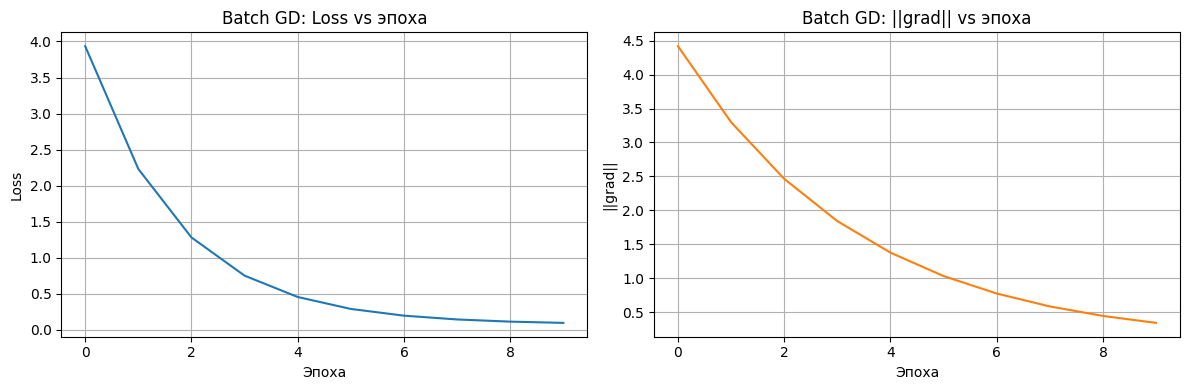

In [ ]:
# Класс MLP был реализован в прошлых уроках

model = MLP([1, 1], activation="tanh")
lr, epochs = 0.1, 10

loss_history = []
grad_norms = []

for epoch in range(1, epochs + 1):
    preds = model.forward(X)
    loss = model.mse(preds, Y)
    loss_history.append(loss)

    model.backward(Y)

    # Соберите ВСЕ градиенты (dW и db) в один плоский вектор
    grads = np.concatenate(
        [np.ravel(dW) for dW in model.dW_list] + [np.ravel(db) for db in model.db_list]
    )

    # 2. Вычислите евклидову норму вектора grads
    norm = np.linalg.norm(grads)
    grad_norms.append(norm)

    model.update_params(lr)

    if epoch % 2 == 0:
        print(f"Epoch {epoch:>2d}: loss={loss:.4f}, ||grad||={grad_norms[-1]:.4f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(loss_history, color="tab:blue")
ax1.set(title="Batch GD: Loss vs эпоха", xlabel="Эпоха", ylabel="Loss")
ax1.grid(True)

ax2.plot(grad_norms, color="tab:orange")
ax2.set(title="Batch GD: ||grad|| vs эпоха", xlabel="Эпоха", ylabel="||grad||")
ax2.grid(True)

plt.tight_layout()
plt.show()

Epoch  1: loss=0.0816
Epoch  2: loss=0.0525
Epoch  3: loss=0.0349
Epoch  4: loss=0.0246
Epoch  5: loss=0.0187
Epoch  6: loss=0.0149
Epoch  7: loss=0.0129
Epoch  8: loss=0.0117
Epoch  9: loss=0.0122
Epoch 10: loss=0.0107


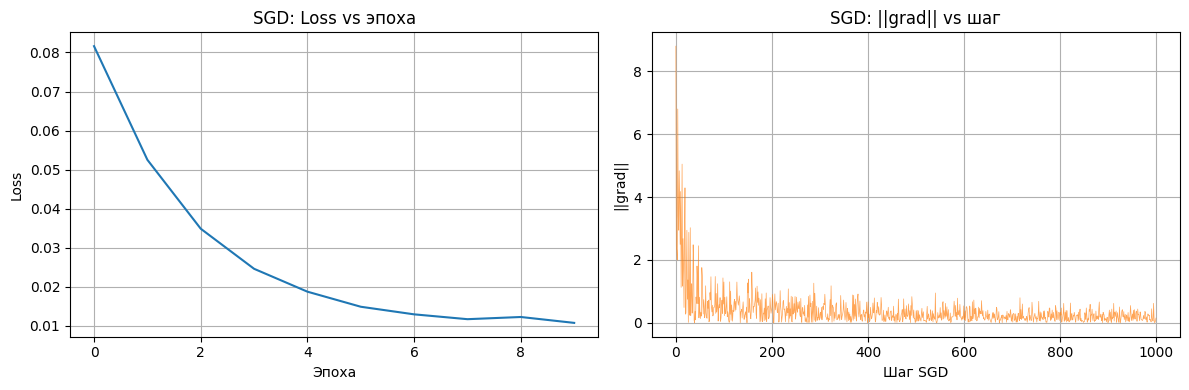

In [4]:
# MLP и данные (X, Y) уже загружены

model = MLP([1, 1], activation="tanh")
lr, epochs = 0.02, 10

loss_history = []
grad_norms = []

for epoch in range(1, epochs + 1):
    # Перемешайте индексы от 0 до len(X)-1
    perm = np.random.permutation(len(X))

    for i in perm:
        # Извлеките один пример: xi shape (1,1), yi shape (1,1)
        xi, yi = X[i : i + 1], Y[i : i + 1]

        # Прямой проход и обратный проход по одному примеру
        model.forward(xi)
        model.backward(yi)

        # Сбор градиентов и нормы (уже знакомо из Задания 2)
        grads = np.concatenate(
            [g.ravel() for g in model.dW_list] + [g.ravel() for g in model.db_list]
        )
        grad_norms.append(np.linalg.norm(grads))
        model.update_params(lr)

    # Loss на всей выборке — считаем после каждой эпохи
    loss = model.mse(model.forward(X), Y)
    loss_history.append(loss)
    print(f"Epoch {epoch:>2d}: loss={loss:.4f}")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(loss_history, color="tab:blue")
ax1.set(title="SGD: Loss vs эпоха", xlabel="Эпоха", ylabel="Loss")
ax1.grid(True)

ax2.plot(grad_norms, color="tab:orange", alpha=0.7, linewidth=0.5)
ax2.set(title="SGD: ||grad|| vs шаг", xlabel="Шаг SGD", ylabel="||grad||")
ax2.grid(True)

plt.tight_layout()
plt.show()

Epoch  1: loss=0.3537
Epoch  2: loss=0.1079
Epoch  3: loss=0.0795
Epoch  4: loss=0.0698
Epoch  5: loss=0.0622
Epoch  6: loss=0.0556
Epoch  7: loss=0.0499
Epoch  8: loss=0.0449
Epoch  9: loss=0.0405
Epoch 10: loss=0.0366


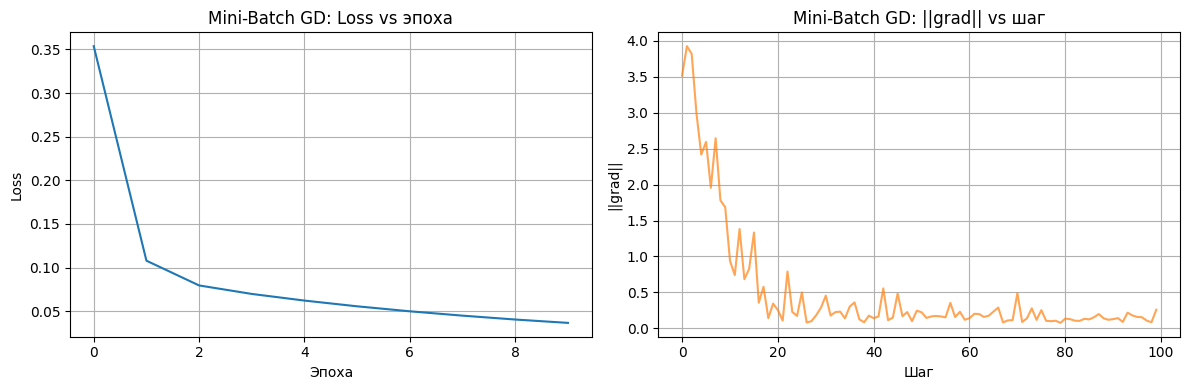

In [5]:
# MLP и данные (X, Y) уже загружены

model = MLP([1, 1], activation="tanh")
lr = 0.05
epochs = 10
batch_size = 10

loss_history = []
grad_norms = []

for epoch in range(1, epochs + 1):
    perm = np.random.permutation(len(X))

    for start in range(0, len(X), batch_size):
        idxs = perm[start : start + batch_size]
        xb, yb = X[idxs], Y[idxs]

        # Прямой и обратный проход по батчу
        model.forward(xb)
        model.backward(yb)

        # Соберите норму градиента (как в заданиях 2–3)
        grads = np.concatenate(
            [g.ravel() for g in model.dW_list] + [g.ravel() for g in model.db_list]
        )

        grad_norms.append(np.linalg.norm(grads))

        # Обновите параметры
        model.update_params(lr)

    # Loss после эпохи
    loss = model.mse(model.forward(X), Y)
    loss_history.append(loss)
    print(f"Epoch {epoch:>2d}: loss={loss:.4f}")

# --- Визуализация (ничего менять не нужно) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(loss_history, color="tab:blue")
ax1.set(title="Mini-Batch GD: Loss vs эпоха", xlabel="Эпоха", ylabel="Loss")
ax1.grid(True)

ax2.plot(grad_norms, color="tab:orange", alpha=0.7)
ax2.set(title="Mini-Batch GD: ||grad|| vs шаг", xlabel="Шаг", ylabel="||grad||")
ax2.grid(True)

plt.tight_layout()
plt.show()